<a href="https://colab.research.google.com/github/Zishan-125/AI__TASK/blob/main/patient_risk_predictor_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Lab 1: Introduction to Python for Data Mining

In [2]:
import pandas as pd

df = pd.read_csv("patient_risk_dataset.csv")
print("First 5 Rows:")
print(df.iloc[:5, [0, 1, 2, 3, -1]])
print("\nDataset Shape:", df.shape)
print("Column Names:", df.columns.tolist()[:5], "... 'risk_label'")
print("Data Types:", df.dtypes.value_counts().to_dict())

# Python basics on patient data
name = "Patient Risk Dataset"; patients = 569; malignant_rate = 0.373; ready = True

features = ["worst_perimeter", "worst_concave_points", "area_error"]  # list
source = ("Wisconsin", "Diagnostic", "Breast Cancer")                  # tuple
info = {"Name": name, "Target": "risk_label (1 = malignant)"}          # dictionary
print("\nVariables:", name, patients, malignant_rate, ready)
print("Tuple:", source, "| Dictionary:", info)
for f in features:
    print("-", f)                                                     # loop
def dataset_rows(data):
    return len(data)                                                  # function
print("Number of Records:", dataset_rows(df))

First 5 Rows:
   mean_radius  mean_texture  mean_perimeter  mean_area  risk_label
0        17.99         10.38          122.80     1001.0           1
1        20.57         17.77          132.90     1326.0           1
2        19.69         21.25          130.00     1203.0           1
3        11.42         20.38           77.58      386.1           1
4        20.29         14.34          135.10     1297.0           1

Dataset Shape: (569, 31)
Column Names: ['mean_radius', 'mean_texture', 'mean_perimeter', 'mean_area', 'mean_smoothness'] ... 'risk_label'
Data Types: {dtype('float64'): 30, dtype('int64'): 1}

Variables: Patient Risk Dataset 569 0.373 True
Tuple: ('Wisconsin', 'Diagnostic', 'Breast Cancer') | Dictionary: {'Name': 'Patient Risk Dataset', 'Target': 'risk_label (1 = malignant)'}
- worst_perimeter
- worst_concave_points
- area_error
Number of Records: 569


Lab 2: Data Preprocessing and Exploration

In [5]:
import pandas as pd
from sklearn.preprocessing import MinMaxScaler, StandardScaler

df = pd.read_csv("patient_risk_dataset.csv")
df = df[["mean_radius", "mean_texture", "worst_perimeter", "worst_concave_points", "area_error", "risk_label"]]

print("Missing Values:", df.isnull().sum().sum())
df.dropna(inplace=True)

print("Duplicate Rows:", df.duplicated().sum())
df.drop_duplicates(inplace=True)

# Encoding categorical variable
df["Risk_Level"] = df["risk_label"].map({0: "Benign", 1: "Malignant"})
print("\nOne-hot encoding counts:\n", pd.get_dummies(df["Risk_Level"]).sum().to_dict())

# Feature scaling
num = df.drop(columns=["risk_label", "Risk_Level"])
minmax = MinMaxScaler().fit_transform(num)
zscore = StandardScaler().fit_transform(num)

print("Min-Max min/max :", minmax.min().round(2), minmax.max().round(2))
print("Z-score mean/std :", zscore.mean().round(2), zscore.std().round(2))
print("\nDescriptive Statistics:")
print(num.describe().round(2))
print("Final Dataset Shape:", df.shape)

Missing Values: 0
Duplicate Rows: 0

One-hot encoding counts:
 {'Benign': 357, 'Malignant': 212}
Min-Max min/max : 0.0 1.0
Z-score mean/std : -0.0 1.0

Descriptive Statistics:
       mean_radius  mean_texture  worst_perimeter  worst_concave_points  \
count       569.00        569.00           569.00                569.00   
mean         14.13         19.29           107.26                  0.11   
std           3.52          4.30            33.60                  0.07   
min           6.98          9.71            50.41                  0.00   
25%          11.70         16.17            84.11                  0.06   
50%          13.37         18.84            97.66                  0.10   
75%          15.78         21.80           125.40                  0.16   
max          28.11         39.28           251.20                  0.29   

       area_error  
count      569.00  
mean        40.34  
std         45.49  
min          6.80  
25%         17.85  
50%         24.53  
75%     

Lab 3: Visualization and Exploratory Data Analysis

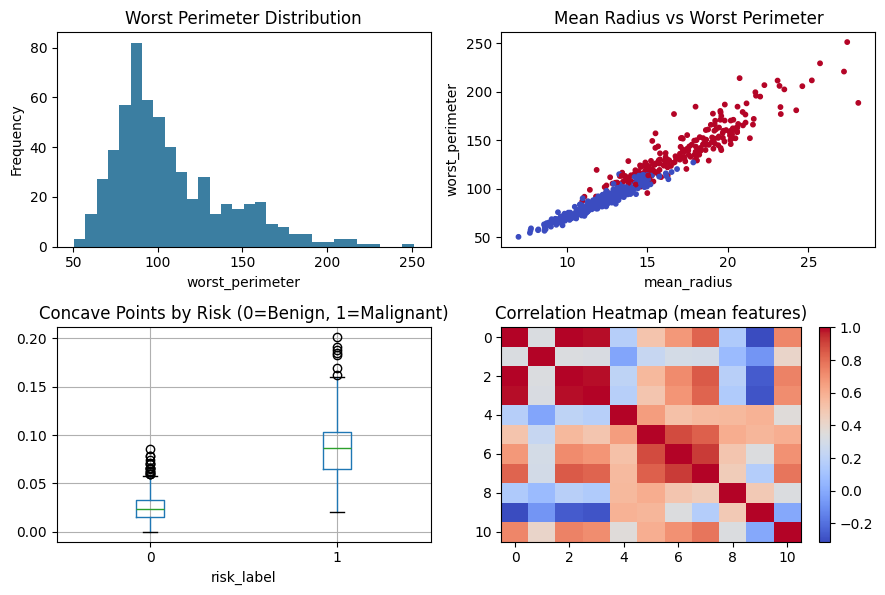

Highest correlation with risk_label:
worst_concave_points    0.794
worst_perimeter         0.783
mean_concave_points     0.777
worst_radius            0.776
mean_perimeter          0.743
Name: risk_label, dtype: float64


In [8]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("patient_risk_dataset.csv")
fig, ax = plt.subplots(2, 2, figsize=(9, 6.2))

ax[0, 0].hist(df["worst_perimeter"], bins=30, color="#3B7EA1")  # histogram
ax[0, 0].set(title="Worst Perimeter Distribution", xlabel="worst_perimeter", ylabel="Frequency")

ax[0, 1].scatter(df["mean_radius"], df["worst_perimeter"], c=df["risk_label"], cmap="coolwarm", s=10)
ax[0, 1].set(title="Mean Radius vs Worst Perimeter", xlabel="mean_radius", ylabel="worst_perimeter")

df.boxplot(column="mean_concave_points", by="risk_label", ax=ax[1, 0])  # box plot
ax[1, 0].set(title="Concave Points by Risk (0=Benign, 1=Malignant)", xlabel="risk_label")
fig.suptitle("")

corr = df[[c for c in df.columns if c.startswith("mean_")] + ["risk_label"]].corr()
im = ax[1, 1].imshow(corr, cmap="coolwarm", aspect="auto")
plt.colorbar(im, ax=ax[1, 1])
ax[1, 1].set(title="Correlation Heatmap (mean features)")

plt.tight_layout()
plt.show()

print("Highest correlation with risk_label:")
print(df.corr()["risk_label"].drop("risk_label").sort_values(ascending=False).head(5).round(3))

Lab 4: Frequent Pattern Mining using Apriori

In [10]:
import pandas as pd
from mlxtend.frequent_patterns import apriori, association_rules

df = pd.read_csv("patient_risk_dataset.csv")

t = pd.DataFrame({
    "Malignant": df["risk_label"] == 1,
    "Benign": df["risk_label"] == 0,
    "Large_Perimeter": df["worst_perimeter"] > df["worst_perimeter"].median(),
    "High_Concavity": df["worst_concave_points"] > df["worst_concave_points"].median(),
    "High_Texture": df["worst_texture"] > df["worst_texture"].median(),
    "Large_Area_Error": df["area_error"] > df["area_error"].median()
})

freq = apriori(t, min_support=0.2, use_colnames=True)
rules = association_rules(freq, metric="confidence", min_threshold=0.8)

fmt = lambda s: ", ".join(sorted(s))
rules["antecedents"] = rules["antecedents"].apply(fmt)
rules["consequents"] = rules["consequents"].apply(fmt)

print("Transactions:", len(t), "| Frequent itemsets:", len(freq), "| Rules:", len(rules))
print(rules[["antecedents", "consequents", "support", "confidence", "lift"]]
      .sort_values("lift", ascending=False).head(6).round(3).to_string(index=False))

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Transactions: 569 | Frequent itemsets: 33 | Rules: 70
                                                    antecedents                 consequents  support  confidence  lift
                 High_Concavity, High_Texture, Large_Area_Error  Large_Perimeter, Malignant    0.241       0.932 2.587
High_Concavity, High_Texture, Large_Area_Error, Large_Perimeter                   Malignant    0.241       0.951 2.553
                 High_Concavity, High_Texture, Large_Area_Error                   Malignant    0.243       0.939 2.520
                High_Texture, Large_Area_Error, Large_Perimeter   High_Concavity, Malignant    0.241       0.884 2.477
                  High_Concavity, High_Texture, Large_Perimeter Large_Area_Error, Malignant    0.241       0.820 2.470
                  High_Concavity, High_Texture, Large_Perimeter                   Malignant    0.269       0.916 2.459


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Lab 5: Frequent Pattern Mining using FP-Growth

In [12]:
import pandas as pd
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules

df = pd.read_csv("patient_risk_dataset.csv")

t = pd.DataFrame({
    "Malignant": df["risk_label"] == 1,
    "Benign": df["risk_label"] == 0,
    "Large_Perimeter": df["worst_perimeter"] > df["worst_perimeter"].median(),
    "High_Concavity": df["worst_concave_points"] > df["worst_concave_points"].median(),
    "High_Texture": df["worst_texture"] > df["worst_texture"].median(),
    "Large_Area_Error": df["area_error"] > df["area_error"].median()
})

fp = fpgrowth(t, min_support=0.2, use_colnames=True)
ap = apriori(t, min_support=0.2, use_colnames=True)

print("FP-Growth itemsets:", len(fp), "| Apriori itemsets:", len(ap))
print("Same itemsets found:", set(fp["itemsets"]) == set(ap["itemsets"]))

rules = association_rules(fp, metric="confidence", min_threshold=0.9)
rules = rules[rules["consequents"] == frozenset({"Malignant"})]
rules["antecedents"] = rules["antecedents"].apply(lambda s: ", ".join(sorted(s)))

print("\nRules predicting Malignant (confidence >= 0.9):")
print(rules[["antecedents", "support", "confidence", "lift"]].sort_values("lift", ascending=False).head(5).round(3).to_string(index=False))

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

FP-Growth itemsets: 33 | Apriori itemsets: 33
Same itemsets found: True

Rules predicting Malignant (confidence >= 0.9):
                                                    antecedents  support  confidence  lift
High_Concavity, High_Texture, Large_Area_Error, Large_Perimeter    0.241       0.951 2.553
                 High_Concavity, High_Texture, Large_Area_Error    0.243       0.939 2.520
                  High_Concavity, High_Texture, Large_Perimeter    0.269       0.916 2.459
                High_Texture, Large_Area_Error, Large_Perimeter    0.246       0.903 2.424


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Lab 6: Classification using Decision Tree

In [14]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

df = pd.read_csv("patient_risk_dataset.csv")
features = ["worst_perimeter", "worst_concave_points", "area_error", "worst_concavity", "mean_compactness", "worst_texture", "worst_symmetry", "worst_smoothness"]
X, y = df[features], df["risk_label"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

models = {}
for crit in ["gini", "entropy"]:
    m = DecisionTreeClassifier(criterion=crit, max_depth=4, random_state=42).fit(X_train, y_train)
    models[crit] = m
    print(f"{crit:8s} -> accuracy {accuracy_score(y_test, m.predict(X_test))*100:.2f}% (depth {m.get_depth()}, leaves {m.get_n_leaves()})")

best = max(models, key=lambda c: accuracy_score(y_test, models[c].predict(X_test)))
pred = models[best].predict(X_test)

print(f"\nClassification Report ({best} tree):")
print(classification_report(y_test, pred, target_names=["Benign", "Malignant"]))
print("Confusion Matrix:\n", confusion_matrix(y_test, pred))

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

gini     -> accuracy 92.98% (depth 4, leaves 11)
entropy  -> accuracy 88.60% (depth 4, leaves 12)

Classification Report (gini tree):
              precision    recall  f1-score   support

      Benign       0.91      0.99      0.95        72
   Malignant       0.97      0.83      0.90        42

    accuracy                           0.93       114
   macro avg       0.94      0.91      0.92       114
weighted avg       0.93      0.93      0.93       114

Confusion Matrix:
 [[71  1]
 [ 7 35]]


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Lab 7: Classification using Gaussian Naive Bayes

In [2]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

df = pd.read_csv("patient_risk_dataset.csv")
features = ["worst_perimeter", "worst_concave_points", "area_error", "worst_concavity", "mean_compactness", "worst_texture", "worst_symmetry", "worst_smoothness"]
X, y = df[features], df["risk_label"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

nb = GaussianNB().fit(X_train, y_train)
pred = nb.predict(X_test)

print(f"Accuracy: {accuracy_score(y_test, pred)*100:.2f}%")
print("Class priors (Benign, Malignant):", nb.class_prior_.round(3))
print("\nClassification Report:")
print(classification_report(y_test, pred, target_names=["Benign", "Malignant"]))
print("Confusion Matrix:\n", confusion_matrix(y_test, pred))

Accuracy: 91.23%
Class priors (Benign, Malignant): [0.626 0.374]

Classification Report:
              precision    recall  f1-score   support

      Benign       0.91      0.96      0.93        72
   Malignant       0.92      0.83      0.88        42

    accuracy                           0.91       114
   macro avg       0.91      0.90      0.90       114
weighted avg       0.91      0.91      0.91       114

Confusion Matrix:
 [[69  3]
 [ 7 35]]


Lab 8: Classification using Support Vector Machine

linear kernel accuracy: 97.37%
rbf    kernel accuracy: 96.49%
Best parameters: {'svm__C': 10, 'svm__gamma': 0.01} | CV accuracy: 0.9736
Tuned SVM test accuracy: 97.37%
              precision    recall  f1-score   support

      Benign       0.96      1.00      0.98        72
   Malignant       1.00      0.93      0.96        42

    accuracy                           0.97       114
   macro avg       0.98      0.96      0.97       114
weighted avg       0.97      0.97      0.97       114



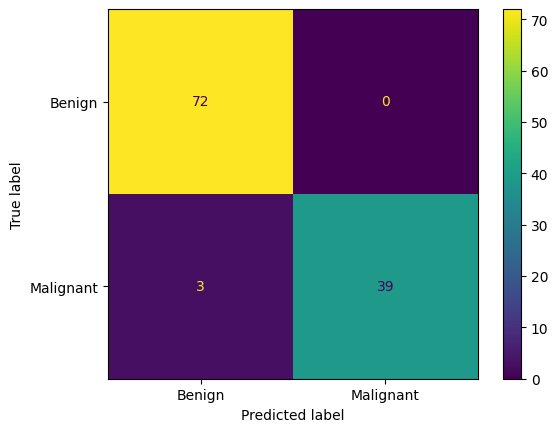

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

df = pd.read_csv("patient_risk_dataset.csv")
features = ["worst_perimeter", "worst_concave_points", "area_error", "worst_concavity", "mean_compactness", "worst_texture", "worst_symmetry", "worst_smoothness"]
X, y = df[features], df["risk_label"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

for k in ["linear", "rbf"]:
    p = Pipeline([("sc", StandardScaler()), ("svm", SVC(kernel=k))]).fit(X_train, y_train)
    print(f"{k:6s} kernel accuracy: {accuracy_score(y_test, p.predict(X_test))*100:.2f}%")

grid = GridSearchCV(
    Pipeline([("sc", StandardScaler()), ("svm", SVC())]),
    {"svm__C": [0.1, 1, 10], "svm__gamma": ["scale", 0.01, 0.1]},
    cv=5
).fit(X_train, y_train)

print("Best parameters:", grid.best_params_, "| CV accuracy:", round(grid.best_score_, 4))

pred = grid.predict(X_test)
print(f"Tuned SVM test accuracy: {accuracy_score(y_test, pred)*100:.2f}%")
print(classification_report(y_test, pred, target_names=["Benign", "Malignant"]))

ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=["Benign", "Malignant"]).plot()
plt.show()

Lab 9: K-Means Clustering

Silhouette (k=2..5): [np.float64(0.398), np.float64(0.249), np.float64(0.213), np.float64(0.184)] | k=3 silhouette: 0.249

Cluster distribution and malignant rate:
         patients  malignant_rate
Cluster                          
0             156           0.667
1             313           0.029
2             100           0.990

Cluster centres (original units, 3 features):
         worst_perimeter  worst_concave_points  area_error
Cluster                                                   
0                 119.14                  0.15       43.99
1                  86.26                  0.07       21.57
2                 154.45                  0.22       93.38


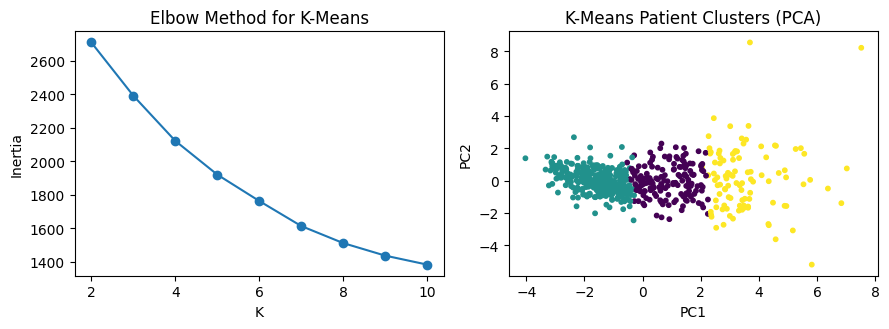

In [5]:
import pandas as pd, matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

df = pd.read_csv("patient_risk_dataset.csv")
features = ["worst_perimeter", "worst_concave_points", "area_error", "worst_concavity",
            "mean_compactness", "worst_texture", "worst_symmetry", "worst_smoothness"]
X = StandardScaler().fit_transform(df[features])

inertia, sil = [], []
for k in range(2, 11):                            # elbow method
    m = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X)
    inertia.append(m.inertia_); sil.append(silhouette_score(X, m.labels_))

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10).fit(X)
df["Cluster"] = kmeans.labels_

print("Silhouette (k=2..5):", [round(s, 3) for s in sil[:4]], "| k=3 silhouette:", round(sil[1], 3))
print("\nCluster distribution and malignant rate:")
print(df.groupby("Cluster")["risk_label"].agg(patients="size", malignant_rate="mean").round(3))
print("\nCluster centres (original units, 3 features):")
print(df.groupby("Cluster")[features[:3]].mean().round(2))

P = PCA(2, random_state=42).fit_transform(X)
fig, ax = plt.subplots(1, 2, figsize=(9, 3.4))
ax[0].plot(range(2, 11), inertia, "o-"); ax[0].set(title="Elbow Method for K-Means", xlabel="K", ylabel="Inertia")
ax[1].scatter(P[:, 0], P[:, 1], c=kmeans.labels_, s=10); ax[1].set(title="K-Means Patient Clusters (PCA)", xlabel="PC1", ylabel="PC2")
plt.tight_layout(); plt.show()

Lab 10: Hierarchical Clustering and DBSCAN

Hierarchical cluster sizes: [135 293 141] | silhouette: 0.183
DBSCAN clusters: 2 | noise points: 56
DBSCAN silhouette (non-noise): 0.3905
Malignant rate in noise points: 0.875


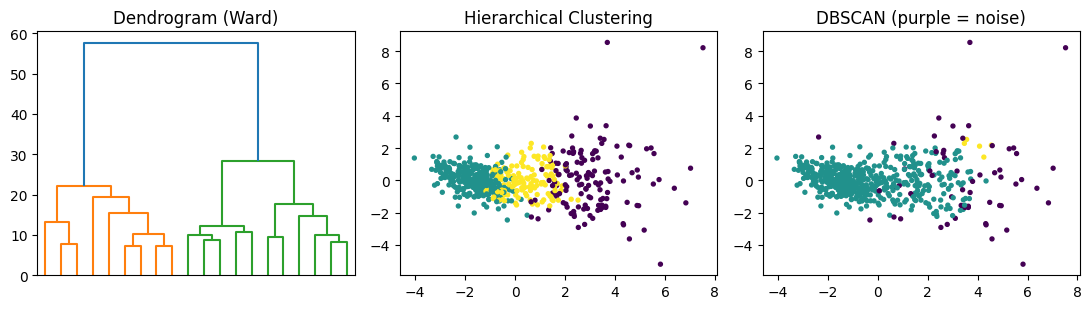

In [7]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from sklearn.cluster import AgglomerativeClustering, DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import linkage, dendrogram

df = pd.read_csv("patient_risk_dataset.csv")
features = ["worst_perimeter", "worst_concave_points", "area_error", "worst_concavity",
            "mean_compactness", "worst_texture", "worst_symmetry", "worst_smoothness"]
X = StandardScaler().fit_transform(df[features])

hier = AgglomerativeClustering(n_clusters=3).fit_predict(X)
print("Hierarchical cluster sizes:", np.bincount(hier), "| silhouette:", round(silhouette_score(X, hier), 4))

db = DBSCAN(eps=1.5, min_samples=5).fit_predict(X)

clusters, noise = len(set(db) - {-1}), int((db == -1).sum())
print("DBSCAN clusters:", clusters, "| noise points:", noise)
mask = db != -1
print("DBSCAN silhouette (non-noise):", round(silhouette_score(X[mask], db[mask]), 4))
print("Malignant rate in noise points:", round(df.loc[~mask, "risk_label"].mean(), 3))

P = PCA(2, random_state=42).fit_transform(X)
fig, ax = plt.subplots(1, 3, figsize=(11, 3.2))
dendrogram(linkage(X, "ward"), truncate_mode="lastp", p=20, no_labels=True, ax=ax[0]); ax[0].set_title("Dendrogram (Ward)")
ax[1].scatter(P[:, 0], P[:, 1], c=hier, s=8); ax[1].set_title("Hierarchical Clustering")
ax[2].scatter(P[:, 0], P[:, 1], c=db, s=8); ax[2].set_title("DBSCAN (purple = noise)")
plt.tight_layout(); plt.show()

Lab 11: Outlier Detection and Ensemble Methods

In [9]:
import pandas as pd
import numpy as np
from sklearn.ensemble import IsolationForest, RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, recall_score, roc_auc_score

df = pd.read_csv("patient_risk_dataset.csv")
features = ["worst_perimeter", "worst_concave_points", "area_error", "worst_concavity", "mean_compactness", "worst_texture", "worst_symmetry", "worst_smoothness"]
num = df[features]

z = np.abs((num - num.mean()) / num.std())
print("Z-Score outliers (|z|>3):", int((z > 3).any(axis=1).sum()))

q1, q3 = num.quantile(0.25), num.quantile(0.75)
iqr = q3 - q1
print("IQR outliers              :", int(((num < q1 - 1.5 * iqr) | (num > q3 + 1.5 * iqr)).any(axis=1).sum()))

iso = IsolationForest(contamination=0.05, random_state=42).fit_predict(num)
print("Isolation Forest (5%)    :", int((iso == -1).sum()), "| malignant share among them:", round(df.loc[iso == -1, "risk_label"].mean(), 3))

X_train, X_test, y_train, y_test = train_test_split(
    df.drop(columns="risk_label"), df["risk_label"],
    test_size=0.2, stratify=df["risk_label"], random_state=42
)

rf = RandomForestClassifier(n_estimators=100, random_state=42).fit(X_train, y_train)
pred = rf.predict(X_test)

print(f"\nRandom Forest accuracy: {accuracy_score(y_test, pred)*100:.2f}% | recall: {recall_score(y_test, pred):.3f} | AUC: {roc_auc_score(y_test, rf.predict_proba(X_test)[:, 1]):.3f}")

print("\nTop feature importances:")
print(pd.Series(rf.feature_importances_, index=X_train.columns).sort_values(ascending=False).head(6).round(4))

Z-Score outliers (|z|>3): 33
IQR outliers              : 99
Isolation Forest (5%)    : 29 | malignant share among them: 0.897

Random Forest accuracy: 97.37% | recall: 0.929 | AUC: 0.993

Top feature importances:
worst_area              0.1514
worst_concave_points    0.1265
worst_radius            0.0935
worst_perimeter         0.0836
mean_concave_points     0.0811
mean_perimeter          0.0771
dtype: float64


Lab 12: End-to-End Mini Project: Patient Risk Prediction

In [11]:
import pandas as pd, numpy as np, joblib
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.cluster import KMeans
from sklearn.ensemble import IsolationForest
from sklearn.metrics import accuracy_score, recall_score, precision_score, roc_auc_score

df = pd.read_csv("patient_risk_dataset.csv")
features = ["worst_perimeter", "worst_concave_points", "area_error", "worst_concavity",
            "mean_compactness", "worst_texture", "worst_symmetry", "worst_smoothness"]
X, y = df[features], df["risk_label"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)
print("Training:", X_train.shape, "| Testing:", X_test.shape)

model = Pipeline([("scaler", StandardScaler()), ("clf", LogisticRegression(max_iter=2000))]).fit(X_train, y_train)
p = model.predict_proba(X_test)[:, 1]; pred = (p >= 0.5).astype(int)
print(f"Accuracy {accuracy_score(y_test, pred):.3f} | Precision {precision_score(y_test, pred):.3f} | "
      f"Recall {recall_score(y_test, pred):.3f} | AUC {roc_auc_score(y_test, p):.3f}")

tier = pd.cut(p, [0, .2, .6, 1.0], labels=["LOW", "MODERATE", "HIGH"], include_lowest=True)
print("\nRisk tiers on test set:")
print(pd.DataFrame({"patients": tier.value_counts(), "malignant_share": y_test.groupby(tier).mean().round(3)}).loc[["LOW", "MODERATE", "HIGH"]])

km = KMeans(3, n_init=10, random_state=42).fit(model.named_steps["scaler"].transform(X))
iso = IsolationForest(contamination=0.05, random_state=42).fit(model.named_steps["scaler"].transform(X_train))
sample = X_test.iloc[[0]]
print("\nSample patient -> risk %.1f%% | cluster %d | anomaly: %s" %
      (100 * model.predict_proba(sample)[0, 1], km.predict(model.named_steps["scaler"].transform(sample))[0],
       iso.predict(model.named_steps["scaler"].transform(sample))[0] == -1))
joblib.dump({"model": model, "features": features, "kmeans": km, "isolation_forest": iso}, "patient_risk_bundle.joblib")
print("Model saved as: patient_risk_bundle.joblib")

Training: (426, 8) | Testing: (143, 8)
Accuracy 0.986 | Precision 1.000 | Recall 0.962 | AUC 0.998

Risk tiers on test set:
          patients  malignant_share
LOW             87            0.011
MODERATE         5            0.200
HIGH            51            1.000


/tmp/ipykernel_152/2489264118.py:24: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(pd.DataFrame({"patients": tier.value_counts(), "malignant_share": y_test.groupby(tier).mean().round(3)}).loc[["LOW", "MODERATE", "HIGH"]])



Sample patient -> risk 100.0% | cluster 0 | anomaly: False
Model saved as: patient_risk_bundle.joblib
